# Reproducing the statistical analysis of "Evaluation of Downy Mildew Resistance in the USDA Hemp Germplasm Repository Using High-Throughput and Traditional Phenotyping Methods" (Herrmann et al. 2026, *Plant Disease*, DOI [10.1094/pdis-09-25-1916-re](https://doi.org/10.1094/pdis-09-25-1916-re))

**Scope (partial demonstration).** This notebook runs the authors' five R Markdown analysis pipelines — `01_Data_Preprocessing` through `05_Rating_Method_Comparison` — from the pinned author repository [th589/HempDownyMildew_Phenotyping](https://github.com/th589/HempDownyMildew_Phenotyping) (commit `da625fb14ec8ee461f94863e9e8e12fe6690dc56`) on the authors' own `Full_dataset.csv`, reproducing the paper's statistical subsection: disease-severity summaries and the comparison of **Blackbird CNN**, **visual leaf-disc**, and **detached-leaf** ratings across 108 hemp entries.

**Out of scope.** The MATLAB CNN (`HempDMNet3.mat`), the MATLAB analyzer/thresholder GUI apps, the image shares, and the R Shiny quick-lookup app are not reproduced here (MATLAB/licensed GUI tooling); this notebook reproduces the statistical comparison only. This is a one-dataset execution of the authors' pipelines — it does not verify dataset-level figures beyond what the pipelines output.

**AI-assisted launcher.** The R analysis code is the authors' own, fetched unmodified at the pinned commit and rendered with `rmarkdown`. The Python launcher/plotting cells around it are AI-written glue; the authors did not provide this Colab notebook.

日本語の概要: このノートブックは著者らの公開リポジトリ（ pinned commit `da625fb1`）から5つのR Markdown解析パイプライン（01〜05）を `Full_dataset.csv` に対してそのまま実行し、Blackbird CNN・葉ディスク目視・離れた葉の目視という3手法の罹病度（severity）集計と比較を再現します。MATLABによるCNN学習・画像解析GUIは対象外です。Rのコードは著者物を改変せず使用し、周辺のPythonセルは本ノートブック用にAIが作成した補助です。

## Runtime selection — CPU is sufficient

**Select Runtime → Change runtime type → CPU** (no GPU is used or needed; this is classical statistics on a 250 KB table). Run all cells top-to-bottom with `Runtime → Run all`.

- Expected duration: ~10–20 minutes total (most time is R package installation; the pipelines themselves take under a minute, measured on a Colab CPU VM in 2026-10).
- Downloads: <1 MB (five `.Rmd` files, `Full_dataset.csv`, README).
- All data stays on the Colab VM under `/content/hbdm`.

日本語: ランタイムはCPUのみで十分です（GPU不要）。全セルを上から実行してください。所要はパッケージ導入込みで10〜20分程度、ダウンロードは1MB未満です。

### Check the runtime has R

The paper's analysis is R code, so this notebook uses Colab's preinstalled R (`/usr/bin/Rscript`) launched from Python. This cell verifies R exists and reports its version, failing explicitly if R is absent (per the known CLI/CLI-version caveat, the kernelspec stays Python 3 and R is invoked via `Rscript`).

日本語: この論文の解析はRコードのため、ColabにプリインストールされたRを `Rscript` 経由で呼び出します。まずRの存在とバージョンを確認します。

In [ ]:
import subprocess, shutil, sys
rscript = shutil.which("Rscript") or "/usr/bin/Rscript"
res = subprocess.run([rscript, "-e", "cat(R.version.string)"], capture_output=True, text=True, timeout=120)
print(res.stdout.strip() or res.stderr.strip())
if res.returncode != 0 or not res.stdout.strip():
    raise RuntimeError("R is not available in this runtime; select a Colab runtime that includes R.")

R version 4.6.1 (2026-06-24)


### Fetch the pinned author code and dataset into the Colab VM

Downloads exactly six files from the pinned commit `da625fb14ec8ee461f94863e9e8e12fe6690dc56` of the authors' repository via `raw.githubusercontent.com`, then verifies each file's Git blob SHA-1 (values taken from the pinned tree listing) before use. Any mismatch aborts the run.

日本語: 著者リポジトリの pinned commit からRmd5本・`Full_dataset.csv`・READMEを取得し、Git blob SHA-1で完全性を検証します。一致しない場合は中断します。

In [ ]:
import urllib.request, subprocess, os
COMMIT = "da625fb14ec8ee461f94863e9e8e12fe6690dc56"
BASE = f"https://raw.githubusercontent.com/th589/HempDownyMildew_Phenotyping/{COMMIT}"
# (relative path in repo, expected git blob SHA-1) -- from the pinned tree listing
FILES = {
    "R_code/01_Data_Preprocessing.Rmd":        "44662e4d5ac423514d1a703cdabd8bce0fa4eaf9",
    "R_code/02_Blackbird_Analysis.Rmd":        "f5bbd7e1a3e4fe073b0b7874ee8cd01afe81e3ff",
    "R_code/03_Leaf_Disc_Analysis.Rmd":        "1b03b781b0afdc3f6adb25f35ec3680d6dc6a3b6",
    "R_code/04_Detached_Leaf_Analysis.Rmd":    "afa6fb44b20328e2745e2b597562dd0762a1da26",
    "R_code/05_Rating_Method_Comparison.Rmd":  "c4aa166f79bd780df34b10dbc4ed76dfe23992bf",
    "R_code/Full_dataset.csv":                 "f3f61401e26be1a52b1e6a5e805f933308c4c9f7",
    "README.md":                               "61e88359ffdef0fb4e96281f606cf77e75423d5b",
}
WORK = "/content/hbdm"
os.makedirs(WORK, exist_ok=True)
for rel, sha in FILES.items():
    dst = os.path.join(WORK, os.path.basename(rel))
    urllib.request.urlretrieve(f"{BASE}/{rel}", dst)
    blob = subprocess.run(["git", "hash-object", dst], capture_output=True, text=True).stdout.strip()
    status = "OK" if blob == sha else "MISMATCH"
    print(f"{rel:45s} {os.path.getsize(dst):>8d} B  blob {blob[:12]}... {status}")
    if blob != sha:
        raise RuntimeError(f"Blob SHA-1 mismatch for {rel}; refusing to continue.")

R_code/01_Data_Preprocessing.Rmd                  2563 B  blob 44662e4d5ac4... OK
R_code/02_Blackbird_Analysis.Rmd                 11121 B  blob f5bbd7e1a3e4... OK


R_code/03_Leaf_Disc_Analysis.Rmd                 10990 B  blob 1b03b781b0af... OK
R_code/04_Detached_Leaf_Analysis.Rmd             11011 B  blob afa6fb44b203... OK


R_code/05_Rating_Method_Comparison.Rmd           11288 B  blob c4aa166f79bd... OK
R_code/Full_dataset.csv                         247879 B  blob f3f61401e26b... OK


README.md                                         2906 B  blob 61e88359ffde... OK


### Input preview — `Full_dataset.csv`

`Full_dataset.csv` (authors' phenotype data; blob `f3f61401…`, 247,879 B) holds severity ratings (0–100%) at 0 and 5–9 days post inoculation (dpi) for three `Rating` methods — `Blackbird` (CNN), `Plot` (visual leaf-disc), `Detached` (detached leaf) — across batches, replicates, isolates, plots/wells/discs and hemp accessions. This cell reports its shape, method counts, and a few rows; values are read from the actual file, not hard-coded.

日本語: `Full_dataset.csv` の構成（行数・列・3評価手法の件数）と先頭行を表示します。数値はすべて実データから動的に取得します。

In [ ]:
import pandas as pd
# The authors' CSV writes missing values as "." (R na.strings="."); parse them as NA
# and force the dpi columns numeric so the preview is robust to pandas type inference.
df = pd.read_csv("/content/hbdm/Full_dataset.csv", na_values=".")
for c in df.columns:
    if c.endswith("dpi"):
        df[c] = pd.to_numeric(df[c], errors="coerce")
print("shape:", df.shape)
print("columns:", list(df.columns))
print(df["Rating"].value_counts().to_string())
print("accessions (unique):", df["Accession"].str.strip().nunique())
print("8dpi dtype:", df[[c for c in df.columns if c.endswith('dpi')][5]].dtype)
df.head(3)

shape: (4875, 14)
columns: ['Rating', 'Batch', 'Rep', 'Isolate', 'Plot', 'Well', 'Disc', 'Accession', '0dpi', '5dpi', '6dpi', '7dpi', '8dpi', '9dpi']
Rating
Blackbird    3750
Plot          750
Detached      375
accessions (unique): 108
8dpi dtype: float64


,Rating,Batch,Rep,Isolate,Plot,Well,Disc,Accession,0dpi,5dpi,6dpi,7dpi,8dpi,9dpi
0,Detached,1,1,22031,NaN,NaN,NaN,G33199,0,0.0,0.0,0.0,0.0,0.0
1,Detached,1,2,22031,NaN,NaN,NaN,G33199,0,0.0,5.0,7.0,7.0,8.0
2,Detached,1,3,22031,NaN,NaN,NaN,G33199,0,0.0,2.0,3.0,3.0,4.0


### Input preview — severity distributions per rating method (generated view)

A quick matplotlib boxplot of the raw `X8dpi` severity (the dpi the pipelines focus on) for each of the three rating methods, computed from the actual CSV. This is an additional view created for this notebook (not an author figure); it shows how the three phenotyping methods' severity distributions relate before the formal analysis.

日本語: 3評価手法ごとの8dpi生罹病度の箱ひげ図（本ノートブック用に追加作成した図であり、著者の図ではありません）。

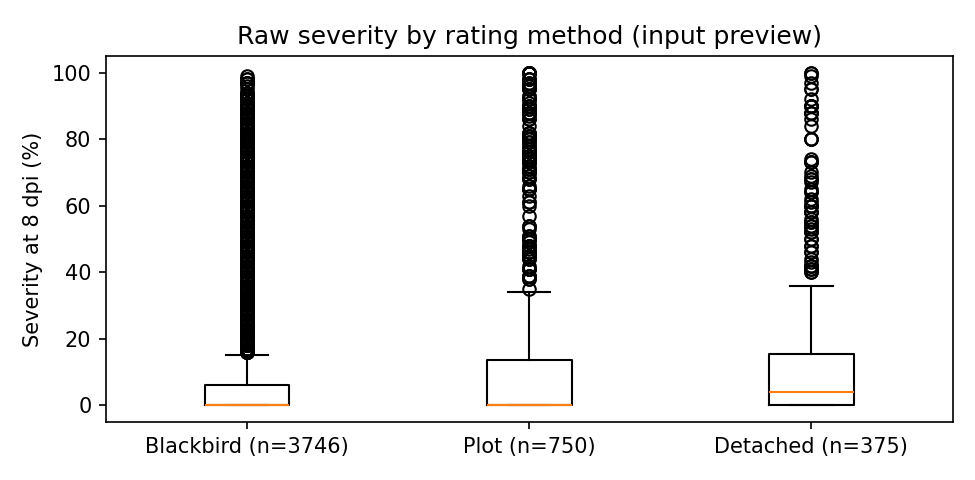

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import Image as IPyImage

methods = ["Blackbird", "Plot", "Detached"]
# pandas keeps the CSV header ("8dpi"); R's read.csv renames it to "X8dpi" for the pipelines.
col8 = "8dpi" if "8dpi" in df.columns else "X8dpi"
data8 = [df.loc[df["Rating"] == m, col8].dropna().values for m in methods]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.boxplot(data8, tick_labels=[f"{m} (n={len(d)})" for m, d in zip(methods, data8)])
ax.set_ylabel("Severity at 8 dpi (%)")
ax.set_title("Raw severity by rating method (input preview)")
fig.tight_layout()
fig.savefig("/content/hbdm/input_preview_8dpi.png", dpi=150)
plt.close(fig)
# display the saved PNG so it is embedded as a durable notebook output
with open("/content/hbdm/input_preview_8dpi.png", "rb") as fh:
    display(IPyImage(fh.read()))

## R package installation

The pipelines use `tidyverse` (preinstalled in the Colab R image) plus `car`, `nlme`, `emmeans`, `multcomp`, `multcompView`, and `patchwork` (verified missing on a fresh Colab CPU VM in this run's diagnostic probe). This cell installs exactly those packages from CRAN, streaming the installer output. Expect ~5–10 minutes.

日本語: パイプラインに必要な未導入のRパッケージ（car, nlme, emmeans, multcomp, multcompView, patchwork）をCRANから導入します（5〜10分、出力はストリーミング表示）。

In [ ]:
import subprocess
pkgs = "car nlme emmeans multcomp multcompView patchwork".split()
check = subprocess.run(["/usr/bin/Rscript", "-e", "ip <- rownames(installed.packages()); cat(paste(intersect(c(%s), ip), collapse=' '))" % ",".join(f"'{p}'" for p in pkgs)], capture_output=True, text=True, timeout=300)
missing = [p for p in pkgs if p not in check.stdout.split()]
print("already installed:", sorted(set(pkgs) - set(missing)) or "none")
print("to install:", missing or "none")
if missing:
    expr = "install.packages(c(%s), repos='https://cloud.r-project.org', Ncpus=2)" % ",".join(f"'{p}'" for p in missing)
    proc = subprocess.Popen(["/usr/bin/Rscript", "-e", expr], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in proc.stdout:
        print(line, end="")
    proc.wait(timeout=2400)
    if proc.returncode != 0:
        raise RuntimeError(f"R package installation failed with exit code {proc.returncode}")

already installed: ['car', 'emmeans', 'multcomp', 'multcompView', 'nlme', 'patchwork']
to install: none


### Verify installed R package versions

Re-checks that every package the pipelines load is now present and prints its actual version, so the executed environment is recorded in the output (versions are shown from the runtime, not hard-coded).

日本語: パイプラインが読み込む全パッケージが導入済みかを再確認し、実行環境のバージョンを記録します。

In [ ]:
import subprocess
res = subprocess.run(["/usr/bin/Rscript", "-e", "for (p in c('tidyverse','car','nlme','emmeans','multcomp','multcompView','patchwork','rmarkdown')) cat(p, as.character(packageVersion(p)), '\n')"], capture_output=True, text=True, timeout=300)
print(res.stdout or res.stderr)

tidyverse 2.0.0 
car 3.1.5 
nlme 3.1.171 
emmeans 2.0.4 
multcomp 1.4.32 
multcompView 0.1.12 
patchwork 1.3.2 
rmarkdown 2.32 



## Run the authors' pipelines 01→05

**Environment adaptation (documented):** pipelines 02–05 write figures to `8dpi/Figures/`, which pre-existed in the authors' working directory but not in a fresh VM, so this notebook creates `8dpi/` and `8dpi/Figures/` first. No author code is modified.

Pipeline order matters: `01` reads `Full_dataset.csv` and writes the per-method averages (`BB_average.csv`, `Plot_average.csv`, `Detached_average.csv`); `02`–`04` each model one method (arcsine-sqrt transform, `nlme` mixed models, Dunnett comparisons vs. resistant checks, BLUP summaries) and write `8dpi/*_Dunnett.csv` etc.; `05` re-reads those outputs for the three-method comparison and correlations. Each pipeline is rendered with `rmarkdown::render` (knit root = the folder containing the files), with timing and explicit failure.

日本語: 著者のパイプライン01→05を順に `rmarkdown::render` で実行します（02〜05の図出力先 `8dpi/Figures/` は新規VMには無いため本ノートブックが作成。著者コード自体は無改変）。実行順序に依存するため必ず01から順に実行します。

### Create the figure output directories

Creates the `8dpi/` and `8dpi/Figures/` folders that pipelines 02–05 write into (the documented environment adaptation — the authors' working directory pre-contained them).

日本語: パイプライン02〜05の図・表の出力先ディレクトリを新規VM向けに作成します。

In [ ]:
import os
os.makedirs("/content/hbdm/8dpi/Figures", exist_ok=True)
print("work dir ready:", sorted(os.listdir("/content/hbdm")))

work dir ready: ['01_Data_Preprocessing.Rmd', '01_Data_Preprocessing.html', '02_Blackbird_Analysis.Rmd', '02_Blackbird_Analysis.html', '03_Leaf_Disc_Analysis.Rmd', '03_Leaf_Disc_Analysis.html', '04_Detached_Leaf_Analysis.Rmd', '04_Detached_Leaf_Analysis.html', '05_Rating_Method_Comparison.Rmd', '05_Rating_Method_Comparison.html', '8dpi', 'BB_average.csv', 'Detached_average.csv', 'Full_dataset.csv', 'Plot_average.csv', 'README.md', 'input_preview_8dpi.png']


### Render pipeline 01 — Data Preprocessing

Defines the `render_pipeline` helper (runs `rmarkdown::render` via `Rscript` in `/content/hbdm`, prints timing and the last lines of any messages, and raises on non-zero exit) and uses it for `01_Data_Preprocessing.Rmd`, which reads `Full_dataset.csv` and writes the three per-method average tables the later pipelines consume.

日本語: `rmarkdown::render` 実行用ヘルパーを定義し、パイプライン01（前処理・3手法の平均表作成）を実行します。

In [ ]:
import subprocess, time
def render_pipeline(name):
    t0 = time.time()
    res = subprocess.run(
        ["/usr/bin/Rscript", "-e", f"rmarkdown::render('{name}', quiet=TRUE)"],
        capture_output=True, text=True, timeout=1800, cwd="/content/hbdm")
    dt = time.time() - t0
    print(f"{name}: exit={res.returncode} in {dt:.1f}s")
    if res.stdout.strip():
        print(res.stdout.strip()[-800:])
    if res.stderr.strip():
        print("STDERR:", res.stderr.strip()[-800:])
    if res.returncode != 0:
        raise RuntimeError(f"{name} failed; see output above.")
    return dt

t01 = render_pipeline("01_Data_Preprocessing.Rmd")

01_Data_Preprocessing.Rmd: exit=0 in 3.0s


### Pipeline 02 — Blackbird CNN rating analysis

Renders `02_Blackbird_Analysis.Rmd`: reads `BB_average.csv`, applies the authors' arcsine-square-root transform, fits their `nlme` models at 8 dpi, runs Dunnett comparisons, exports `8dpi/BB_Dunnett.csv`/`BB_emmeans.csv`/`BB_BLUP.csv`, and saves the author figure `8dpi/Figures/Blackbird_8dpi.tiff`.

日本語: パイプライン02（Blackbird CNN評価の解析）を実行し、Dunnett比較・BLUP表と著者の図を出力します。

In [ ]:
t02 = render_pipeline("02_Blackbird_Analysis.Rmd")

02_Blackbird_Analysis.Rmd: exit=0 in 10.4s


### Pipeline 03 — visual leaf-disc rating analysis

Renders `03_Leaf_Disc_Analysis.Rmd` on `Plot_average.csv` (same statistical recipe as 02), exporting `8dpi/Plot_*` tables and `LeafDisc_8dpi.tiff`.

日本語: パイプライン03（葉ディスク目視評価の解析）を実行します。

In [ ]:
t03 = render_pipeline("03_Leaf_Disc_Analysis.Rmd")

03_Leaf_Disc_Analysis.Rmd: exit=0 in 10.9s


### Pipeline 04 — detached-leaf rating analysis

Renders `04_Detached_Leaf_Analysis.Rmd` on `Detached_average.csv`, exporting `8dpi/Detached_*` tables and `Detached_8dpi.tiff`.

日本語: パイプライン04（離れた葉の目視評価の解析）を実行します。

In [ ]:
t04 = render_pipeline("04_Detached_Leaf_Analysis.Rmd")

04_Detached_Leaf_Analysis.Rmd: exit=0 in 9.5s


### Pipeline 05 — rating-method comparison (requires 02–04 outputs)

Renders `05_Rating_Method_Comparison.Rmd`, which re-reads the three `*_Dunnett.csv` tables, computes resistance flags, top-10 susceptible entries, cross-method correlations, and saves `8dpi/Figures/Method_Correlations.tiff`.

日本語: パイプライン05（3手法の比較・相関）を実行します。02〜04の出力に依存するため必ず後回しにします。

In [ ]:
t05 = render_pipeline("05_Rating_Method_Comparison.Rmd")
print(f"pipeline totals (s): 01={t01:.1f} 02={t02:.1f} 03={t03:.1f} 04={t04:.1f} 05={t05:.1f}")

05_Rating_Method_Comparison.Rmd: exit=0 in 13.7s
pipeline totals (s): 01=3.0 02=10.4 03=10.9 04=9.5 05=13.7


## Results

### Pipeline outputs on disk

Lists every table and figure the five pipelines produced under `/content/hbdm/8dpi/`, so all artifacts are visible and can be downloaded from the Colab file browser.

日本語: パイプラインが生成した成果物一覧を表示します（Colabのファイルブラウザからダウンロード可能）。

In [ ]:
import glob, os
for p in sorted(glob.glob("/content/hbdm/8dpi/**/*", recursive=True)):
    if os.path.isfile(p):
        print(f"{p.replace('/content/hbdm/', ''):55s} {os.path.getsize(p):>9d} B")
print("HTML reports:", [os.path.basename(p) for p in sorted(glob.glob('/content/hbdm/*.html'))])

8dpi/BB_BLUP.csv                                             6658 B
8dpi/BB_Dunnett.csv                                          4566 B
8dpi/BB_emmeans.csv                                          9601 B
8dpi/Detached_BLUP.csv                                       6526 B
8dpi/Detached_Dunnett.csv                                    4441 B
8dpi/Figures/Blackbird_8dpi.tiff                           457844 B
8dpi/Figures/Detached_8dpi.tiff                            451192 B
8dpi/Figures/LeafDisc_8dpi.tiff                            508434 B
8dpi/Figures/Method_Correlations.tiff                     1033168 B
8dpi/Observed_Resistance_Flags.csv                           8705 B
8dpi/Plot_BLUP.csv                                           6683 B
8dpi/Plot_Dunnett.csv                                        4578 B
8dpi/Plot_emmeans.csv                                        9538 B
8dpi/Top10_Observed_Susceptible.csv                           738 B
8dpi/detached_emmeans.csv                       

### Resistance flags and most-susceptible entries

`05` writes `Observed_Resistance_Flags.csv` (per-entry 8 dpi Dunnett comparison against the resistant checks across all three methods) and `Top10_Observed_Susceptible.csv`. Both are shown as they were produced by the authors' code.

日本語: パイプライン05が出力した耐性フラグ表と最も感受性の高い10品種表を表示します。

In [ ]:
import pandas as pd
flags = pd.read_csv("/content/hbdm/8dpi/Observed_Resistance_Flags.csv")
print("flags shape:", flags.shape)
display(flags.head(12))
top10 = pd.read_csv("/content/hbdm/8dpi/Top10_Observed_Susceptible.csv")
display(top10)

flags shape: (108, 13)


,Accession,BB_all_below_5,BB_all_below_1,BB_all_zero,Plot_all_below_5,Plot_all_below_1,Plot_all_zero,Detached_all_below_5,Detached_all_below_1,Detached_all_zero,all_methods_below_5,all_methods_below_1,all_methods_zero
0,AC/DC,False,False,False,False,False,False,False,False,False,False,False,False
1,BaOx,False,False,False,False,False,False,False,False,False,False,False,False
2,Bialobrzeskie,False,False,False,False,False,False,True,False,False,False,False,False
3,Blue Kross,False,False,False,False,False,False,False,False,False,False,False,False
4,CFX-2,False,False,False,False,False,False,False,False,False,False,False,False
5,Carmagnola,False,False,False,False,False,False,False,False,False,False,False,False
6,Cherry Wine,False,False,False,False,False,False,False,False,False,False,False,False
7,FL 58,False,False,False,False,False,False,False,False,False,False,False,False
8,Fibror 79,False,False,False,False,False,False,False,False,False,False,False,False
9,G33199,False,False,False,False,False,False,False,False,False,False,False,False


,Accession,BB_mean,Plot_mean,Detached_mean,Average_Severity
0,G33312,60.000000,88.000000,88.666667,78.888889
1,G33533,70.133333,85.666667,75.333333,77.044444
2,G33338,68.533333,80.000000,79.000000,75.844444
3,G33270,62.466667,77.166667,84.666667,74.766667
4,Otto II,54.466667,73.333333,53.666667,60.488889
5,G33256,58.600000,68.333333,51.000000,59.311111
6,G33557,57.733333,66.666667,46.666667,57.022222
7,G33350,52.266667,60.366667,52.333333,54.988889
8,G33348,58.066667,62.000000,43.000000,54.355556
9,G33540,57.066667,79.333333,26.000000,54.133333


### Per-method Dunnett comparison tables (head)

The first rows of each method's `8dpi/*_Dunnett.csv` (entry-level estimates vs. resistant checks). Columns are shown as produced by the pipelines.

日本語: 各手法のDunnett比較表の先頭行を、パイプラインが出力したままの列名で表示します。

In [ ]:
import pandas as pd
for m in ["BB", "Plot", "Detached"]:
    t = pd.read_csv(f"/content/hbdm/8dpi/{m}_Dunnett.csv")
    print(f"--- {m}_Dunnett.csv  shape={t.shape}")
    display(t.head(5))

--- BB_Dunnett.csv  shape=(108, 7)


,Accession,X8dpi_mean,X8dpi_stderr,G33312_p.value,G33312_significant,G33379_p.value,G33379_significant
0,AC/DC,20.2667,10.8261,0.5653,No,0.1633,No
1,BaOx,26.4000,23.6477,0.2993,No,0.3048,No
2,Bialobrzeskie,8.3333,7.2520,0.4239,No,0.2062,No
3,Blue Kross,41.0000,10.8167,0.2917,No,0.2426,No
4,CFX-2,46.0000,4.2771,0.2420,No,0.0014,Yes


--- Plot_Dunnett.csv  shape=(108, 7)


,Accession,X8dpi_mean,X8dpi_stderr,G33312_p.value,G33312_significant,G33379_p.value,G33379_significant
0,AC/DC,29.0000,15.5027,0.1770,No,0.1976,No
1,BaOx,29.0667,28.4676,0.0554,No,0.4058,No
2,Bialobrzeskie,8.6667,7.6667,0.1027,No,0.2639,No
3,Blue Kross,61.6667,17.4005,0.1459,No,0.1323,No
4,CFX-2,55.3333,10.3494,0.9502,No,0.0075,Yes


--- Detached_Dunnett.csv  shape=(108, 7)


,Accession,X8dpi_mean,X8dpi_stderr,G33312_p.value,G33312_significant,G33379_p.value,G33379_significant
0,AC/DC,9.6667,5.4874,0.0479,Yes,0.4898,No
1,BaOx,22.0000,12.4231,0.1847,No,0.1393,No
2,Bialobrzeskie,1.7333,1.6344,0.0213,Yes,0.6200,No
3,Blue Kross,42.6667,19.9694,0.0069,Yes,0.6122,No
4,CFX-2,8.3333,1.6667,0.0774,No,0.2995,No


### Author figures (TIFF → PNG, displayed as produced)

The pipelines save their figures as TIFF. This cell converts the four author-generated TIFFs to PNG in-memory and displays them unchanged in content: the per-method 8 dpi entry figures from pipelines 02–04 and the cross-method correlation figure from pipeline 05. These are the actual pipeline outputs of this run, not reproductions of published figure images.

日本語: パイプラインが出力したTIFF図4枚をPNGに変換して表示します（内容はパイプライン出力そのもの）。

8dpi/Figures/Blackbird_8dpi.tiff -> (1100, 762)


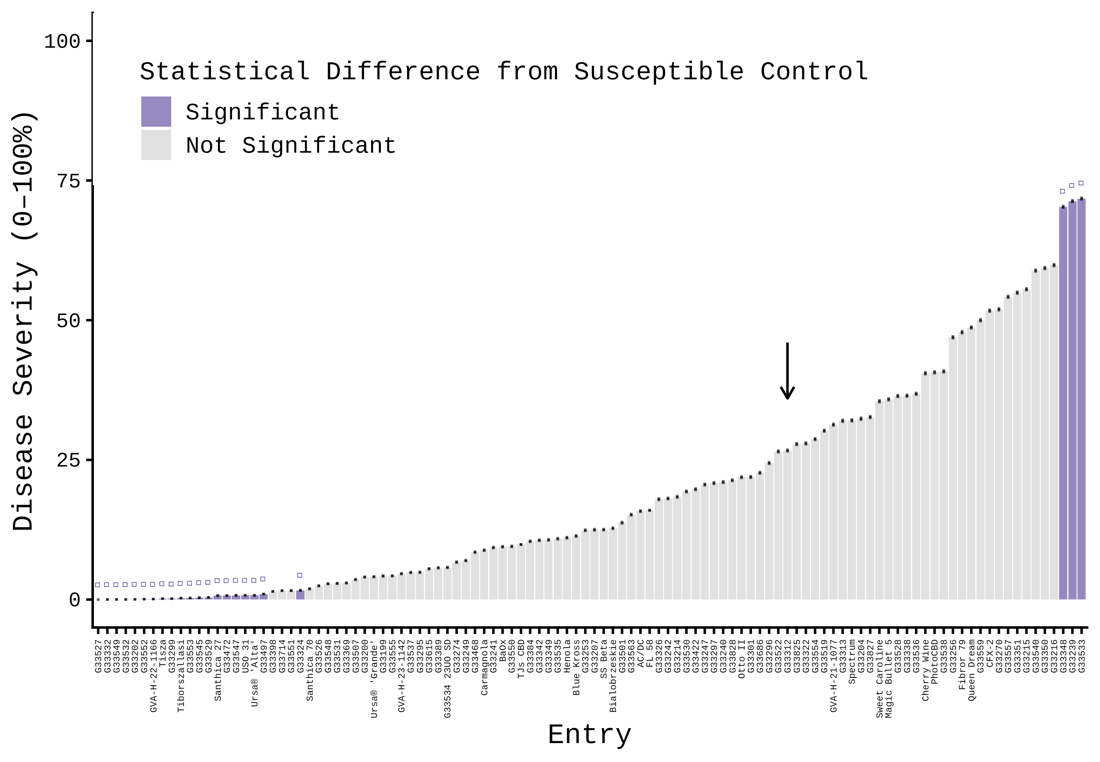

8dpi/Figures/LeafDisc_8dpi.tiff -> (1100, 762)


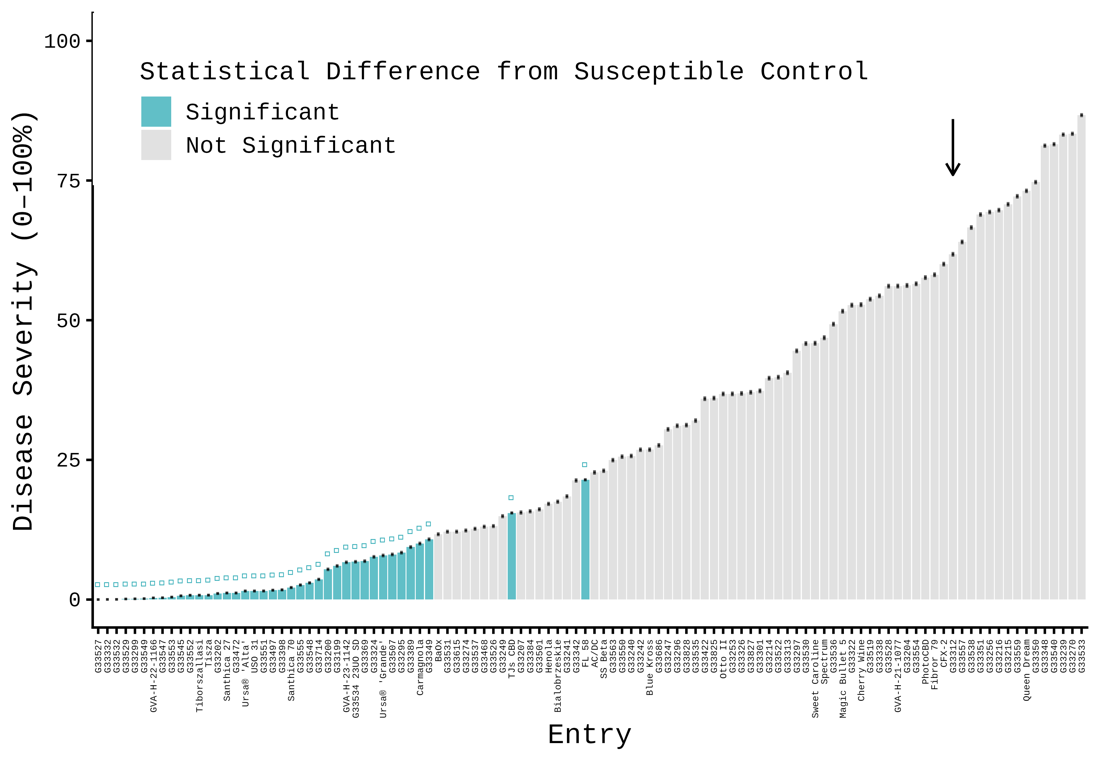

8dpi/Figures/Detached_8dpi.tiff -> (1100, 762)


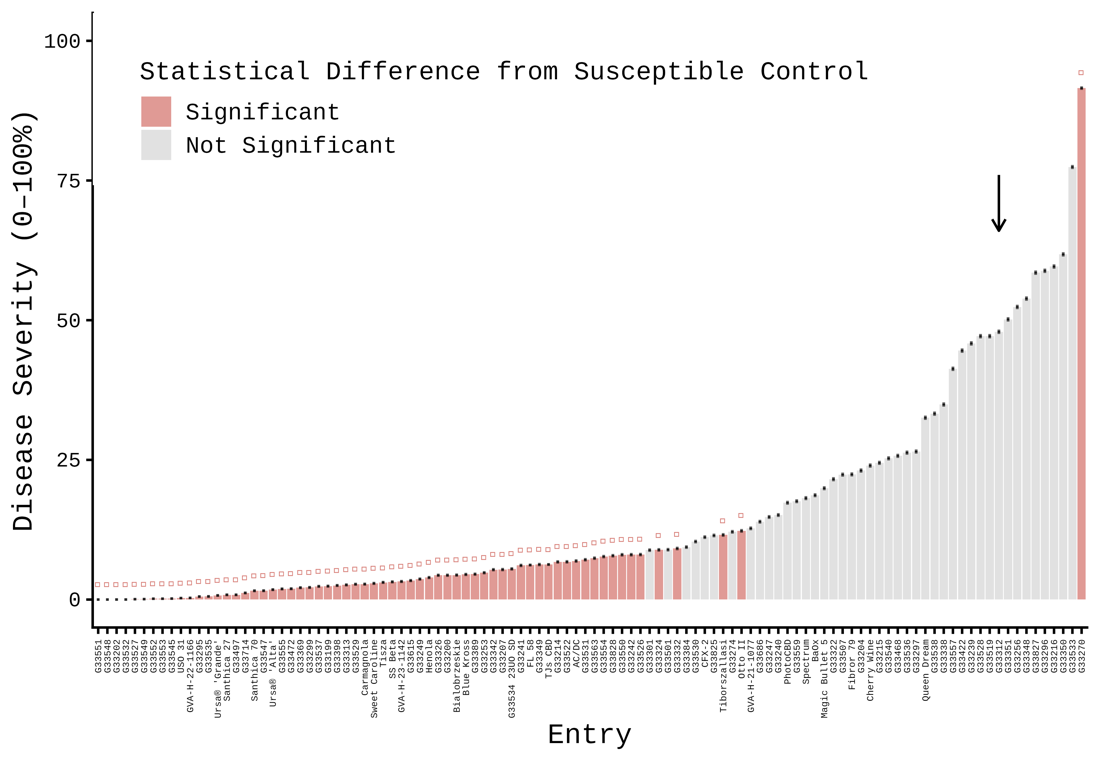

8dpi/Figures/Method_Correlations.tiff -> (1100, 880)


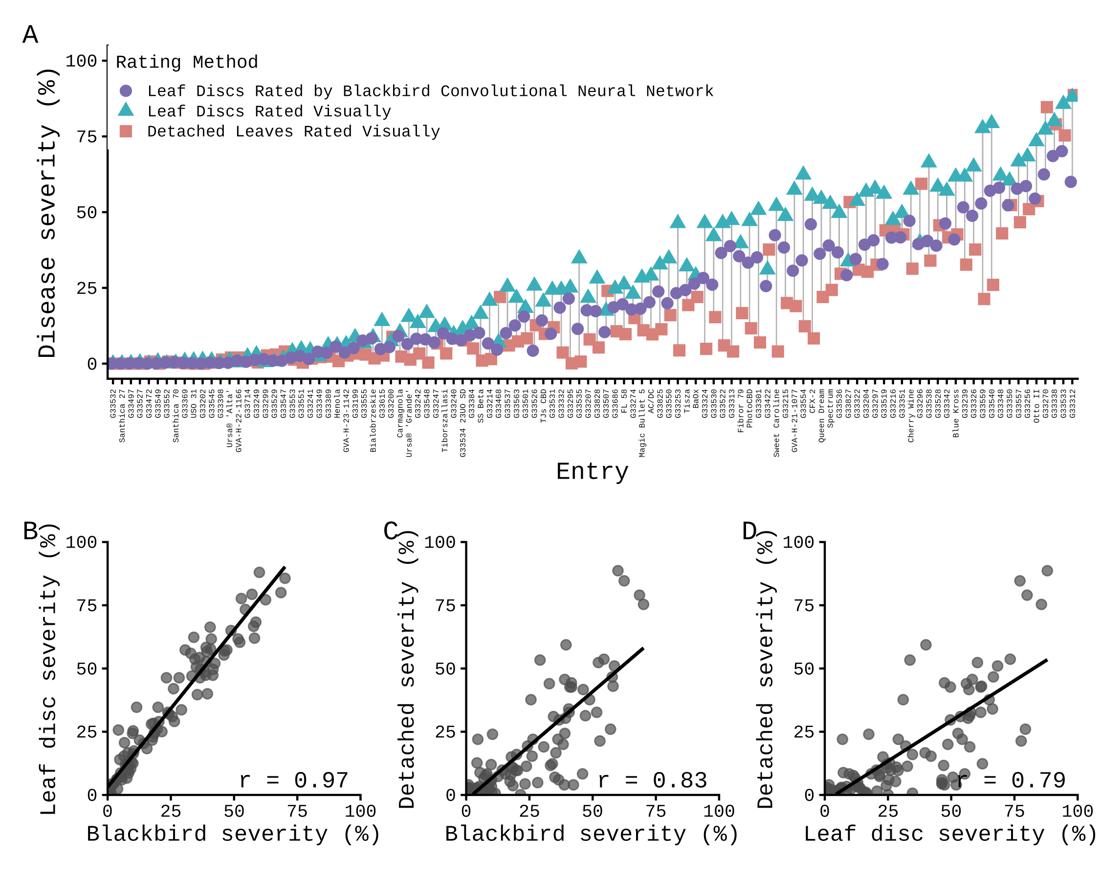

In [ ]:
from PIL import Image
import io
from IPython.display import Image as IPyImage

figs = ["8dpi/Figures/Blackbird_8dpi.tiff", "8dpi/Figures/LeafDisc_8dpi.tiff",
        "8dpi/Figures/Detached_8dpi.tiff", "8dpi/Figures/Method_Correlations.tiff"]
for rel in figs:
    img = Image.open("/content/hbdm/" + rel).convert("RGB")
    img.thumbnail((1100, 1100))
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    print(rel, "->", img.size)
    display(IPyImage(buf.getvalue()))

## Quantitative check against the paper's reported patterns

The paper's abstract (as recorded in the PhenoPaper investigation evidence, sentences 6–10) states: susceptibility ranged from 0 to 100% with two entries — G 33532 and 'Santhica 27' — at 0% severity, and detached-leaf assays produced the lowest severity estimates while Blackbird CNN ratings were higher. This cell computes those quantities directly from the pipeline-produced average tables and prints the observed values for comparison — an independent plausibility check of this run, not a re-derivation of the paper's full results.

日本語: 論文アブストラクトに記載の「0%の2品種（G 33532, Santhica 27）」「手法間の罹病度の大小関係」を、実行結果の平均表から動的に計算して照合します。

In [ ]:
import pandas as pd
means = {}
for name, f in [("Blackbird", "BB_average.csv"), ("Plot (leaf disc)", "Plot_average.csv"), ("Detached leaf", "Detached_average.csv")]:
    t = pd.read_csv("/content/hbdm/" + f)
    means[name] = t["X8dpi"].mean()
print("Mean 8dpi severity by method (%):")
for k, v in means.items():
    print(f"  {k:18s} {v:.1f}")
print("Lowest-method check (abstract: detached leaf lowest):",
      min(means, key=means.get))

zero = {}
for name, f in [("Blackbird", "BB_average.csv"), ("Plot (leaf disc)", "Plot_average.csv"), ("Detached leaf", "Detached_average.csv")]:
    t = pd.read_csv("/content/hbdm/" + f)
    z = sorted(t.loc[t["X8dpi"] == 0, "Accession"].str.strip().unique())
    zero[name] = z
    print(f"Entries at 0% 8dpi ({name}): {z}")

Mean 8dpi severity by method (%):
  Blackbird          21.2
  Plot (leaf disc)   29.3
  Detached leaf      15.8
Lowest-method check (abstract: detached leaf lowest): Detached leaf
Entries at 0% 8dpi (Blackbird): ['AC/DC', 'Cherry Wine', 'G33199', 'G33200', 'G33202', 'G33204', 'G33207', 'G33242', 'G33249', 'G33295', 'G33297', 'G33299', 'G33313', 'G33322', 'G33324', 'G33332', 'G33342', 'G33369', 'G33384', 'G33389', 'G33398', 'G33422', 'G33472', 'G33497', 'G33507', 'G33522', 'G33527', 'G33531', 'G33532', 'G33534 23UO SD', 'G33537', 'G33545', 'G33547', 'G33548', 'G33549', 'G33553', 'GVA-H-22-1166', 'SS Beta', 'Santhica 27', 'Santhica 70', 'Spectrum', 'Sweet Caroline', 'TJs CBD', 'USO 31', "Ursa® 'Alta'"]
Entries at 0% 8dpi (Plot (leaf disc)): ['AC/DC', 'Cherry Wine', 'FL 58', 'G33199', 'G33200', 'G33202', 'G33207', 'G33242', 'G33313', 'G33324', 'G33332', 'G33342', 'G33369', 'G33384', 'G33389', 'G33398', 'G33472', 'G33497', 'G33522', 'G33526', 'G33527', 'G33529', 'G33531', 'G33532', 'G33534

## Interpretation and limitations

- **What was verified:** the authors' five R pipelines ran end-to-end, unmodified, on their own `Full_dataset.csv` at pinned commit `da625fb1`; all exported tables and figures above are this run's actual outputs. The 0–100% severity range, zero-severity entries, and method ordering can be checked against the printed values.
- **What is not claimed:** this single execution does not re-verify every number or figure in the paywalled paper (full text was not accessible; APS returned 403 during investigation). Training/inference of the Blackbird CNN (`HempDMNet3.mat`, MATLAB) and the image shares are out of scope.
- **Environment adaptations (documented, no author-code edits):** fresh-VM creation of `8dpi/Figures/`, plus installation of the CRAN packages listed above. Author code files are fetched unmodified and hash-verified.
- **License:** the repository showed no license file at the pinned commit; author code is executed for study, attributed, and not redistributed as a derived work.

日本語: 著者のRパイプライン5本を無改変のまま実行し、表・図はすべて本実行の実出力です。論文本文（有料）全体の再検証ではなく、CNN学習等は対象外です。著者コードは改変せず、ライセンス表記がないため派生物として再配布しません。

## References

- Herrmann, T. Q., Cox, K., Gordon, T., Stansell, Z., Cadle-Davidson, L., Underhill, A., Ackerman, A. J., Beil, C. T., Sheehan, M. J., Smart, C. D. (2026). Evaluation of Downy Mildew Resistance in the USDA Hemp Germplasm Repository Using High-Throughput and Traditional Phenotyping Methods. *Plant Disease*. DOI: [10.1094/pdis-09-25-1916-re](https://doi.org/10.1094/pdis-09-25-1916-re)
- Author code & data: https://github.com/th589/HempDownyMildew_Phenotyping @ `da625fb14ec8ee461f94863e9e8e12fe6690dc56` (fetched inside this notebook; blob SHA-1 verified).
- R packages: tidyverse, nlme, emmeans, multcomp, multcompView, patchwork, car, rmarkdown (versions printed during execution).